# Sprint 1 · EDA del precio de bolsa nacional (SIMEM)

Objetivo: entender la calidad y la dinámica del precio horario `PB_Nal` (COP/kWh, hora colombiana). Primero ejecuta `python -m src.data.make_dataset` desde la raíz. El análisis principal no descarga ni modifica datos crudos. Define `SIMEM_SNAPSHOT` con la ruta de un snapshot para reproducir un análisis específico; si no se define, se usa el más reciente. La sección 7 permite consultar SINERGOX/XM de forma independiente.

In [1]:
import json
import logging
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss

cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents) if (p / 'config' / 'config.yaml').is_file()), None)
if root is None:
    raise FileNotFoundError('Abre el notebook dentro del repositorio.')
sys.path.insert(0, str(root))
from src.config import read_config_mapping
from src.data.make_dataset import read_snapshot
from src.utils.logger import log_event

config = read_config_mapping(root / 'config' / 'config.yaml')
raw_dir = root / config['paths']['data']['raw'] / 'simem'
if pinned := os.getenv('SIMEM_SNAPSHOT'):
    snapshot = root / pinned
else:
    manifests = sorted(p for p in raw_dir.glob('*/*/manifest.json') if not p.parent.name.startswith('.'))
    if not manifests:
        raise FileNotFoundError('Ejecuta python -m src.data.make_dataset o define SIMEM_SNAPSHOT.')
    snapshot = manifests[-1].parent

manifest = json.loads((snapshot / 'manifest.json').read_text(encoding='utf-8'))
settings = manifest['settings']
figures = root / config['paths']['reports']['figures'] / 'simem' / snapshot.parent.name / snapshot.name
figures.mkdir(parents=True, exist_ok=True)

def export(fig, name):
    path = figures / f'{name}.png'
    fig.savefig(path, dpi=160, bbox_inches='tight', facecolor='white')
    log_event(logging.INFO, 'figure_exported', source='SIMEM', path=path)
    plt.show()
    plt.close(fig)

price = read_snapshot(snapshot, 'precio_bolsa').set_index(settings['timestamp_column'])[settings['target_column']]
log_event(logging.INFO, 'snapshot_loaded', path=snapshot, figures=figures, rows=len(price))
display(manifest['window'], manifest['datasets']['precio_bolsa']['spec'], price.describe())

Snapshot: D:\deep-learning-ws\data\raw\simem\2026-11-18\142406865042Z_ae6cb3e1
Figuras: D:\deep-learning-ws\reports\figures\simem\2026-11-18\142406865042Z_ae6cb3e1


{'start': '2024-03-01', 'end': '2024-04-30'}

{'dataset_id': 'EC6945',
 'timestamp': 'FechaHora',
 'value': 'Valor',
 'frequency': '1h',
 'filters': {'CodigoVariable': 'PB_Nal',
  'Version': 'TX5',
  'CodigoDuracion': 'PT1H',
  'UnidadMedida': 'COP/kWh'},
 'dimensions': [],
 'group_by': [],
 'aggregate': False,
 'revision': None}

count    1464.000000
mean      684.571965
std       288.501488
min        96.364100
25%       522.006700
50%       641.905400
75%       993.521100
max      1267.593400
Name: precio_bolsa, dtype: float64

## 1. Cobertura y faltantes

Reconstruimos la malla de toda la ventana solicitada, incluidos los extremos. Separamos horas sin registro de registros con valor nulo. La cobertura por día revela huecos que un conteo global puede ocultar; no imputamos ni interpretamos un faltante como cero.

,horas,porcentaje
Sin registro,0,0.0
Valor nulo,0,0.0


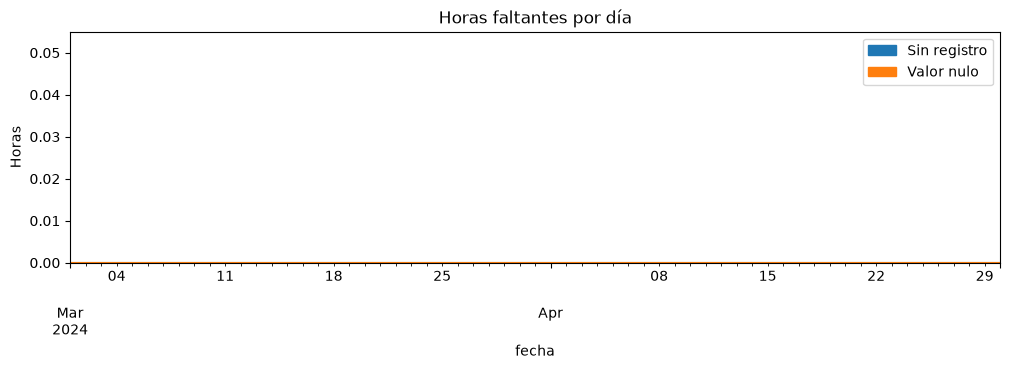

In [2]:
tz = settings['timezone']
first = pd.Timestamp(manifest['window']['start'], tz=tz)
stop = pd.Timestamp(manifest['window']['end'], tz=tz) + pd.DateOffset(days=1)
grid = pd.date_range(first, stop, inclusive='left', freq=settings['frequency'], name=price.index.name)
y = price.reindex(grid)
missing_hours = ~grid.isin(price.index)
quality = pd.DataFrame({'Sin registro': missing_hours, 'Valor nulo': y.isna() & ~missing_hours}, index=grid)
display(pd.DataFrame({'horas': quality.sum(), 'porcentaje': quality.mean().mul(100)}))
daily_quality = quality.resample('D').sum()
fig, ax = plt.subplots(figsize=(12, 3))
daily_quality.plot.area(stacked=True, ax=ax, title='Horas faltantes por día', ylabel='Horas')
export(fig, '01_faltantes')

## 2. Picos de precio y estacionalidad de calendario

Marcamos valores por encima de `Q3 + 3 × IQR` dentro de cada hora del día; si el IQR es cero o hay menos de ocho observaciones, usamos el percentil 99 global como referencia visual. Los picos quedan intactos: un atípico estadístico no acredita que se haya activado el precio de escasez. Para confirmarlo se necesita la serie regulatoria aplicable y la fecha de vigencia.

El mapa horario por día de semana muestra medianas; compáralas con la cobertura antes de interpretar el patrón.

,precio,umbral
fecha,,


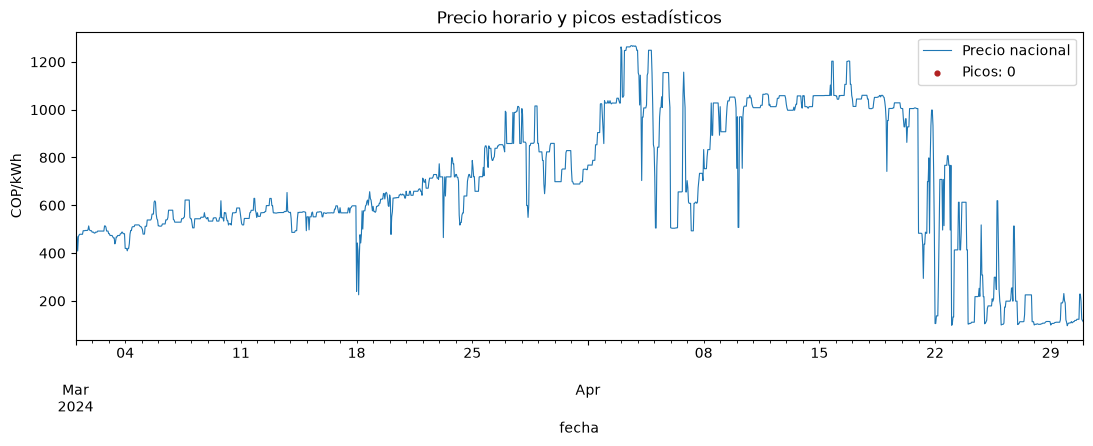

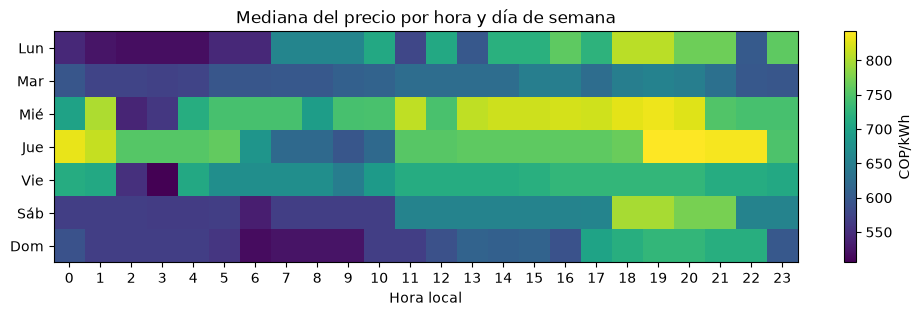

In [3]:
by_hour = y.groupby(y.index.hour)
q1, q3 = by_hour.quantile(.25), by_hour.quantile(.75)
iqr = q3 - q1
limits = (q3 + 3 * iqr).where((iqr > 0) & (by_hour.count() >= 8), y.quantile(.99))
threshold = pd.Series(y.index.hour.map(limits), index=y.index)
peaks = y[y.gt(threshold)]
display(pd.DataFrame({'precio': peaks, 'umbral': threshold.reindex(peaks.index)}).nlargest(20, 'precio'))

fig, ax = plt.subplots(figsize=(13, 4))
y.plot(ax=ax, label='Precio nacional', lw=.8)
ax.scatter(peaks.index, peaks, s=12, color='firebrick', label=f'Picos: {len(peaks)}')
ax.set(title='Precio horario y picos estadísticos', ylabel='COP/kWh')
ax.legend()
export(fig, '02_picos')

profile = y.groupby([y.index.dayofweek, y.index.hour]).median().unstack().reindex(index=range(7), columns=range(24))
fig, ax = plt.subplots(figsize=(12, 3))
heat = ax.imshow(profile.to_numpy(), aspect='auto')
ax.set(xticks=range(24), yticks=range(7), yticklabels=['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'],
       xlabel='Hora local', title='Mediana del precio por hora y día de semana')
fig.colorbar(heat, ax=ax, label='COP/kWh')
export(fig, '03_perfil_calendario')

## 3. Estacionariedad: ADF y KPSS

Usamos el tramo continuo observado más largo (hasta 90 días, tomando el final de ese tramo). Concatenar horas a ambos lados de un hueco alteraría los rezagos. Comparamos nivel y primera diferencia, sin recortar picos. ADF tiene como nula una raíz unitaria y KPSS, estacionariedad alrededor de un nivel constante. Con α = 0,05, rechazar ADF sin rechazar KPSS apoya estacionariedad; resultados contradictorios son inconclusos y pueden reflejar rupturas, estacionalidad o baja potencia. Los p-valores de KPSS fuera de la tabla son límites, no estimaciones exactas.

In [4]:
observed = y.notna()
runs = y[observed].groupby(observed.ne(observed.shift()).cumsum()[observed])
block = max((series for _, series in runs), key=len).iloc[-90 * 24:]
print(f'Tramo continuo: {len(block)} h, {block.index[0]} → {block.index[-1]}')
series_to_test = {'Nivel': block, 'Primera diferencia': block.diff().iloc[1:]}
test_results = []
for label, series in series_to_test.items():
    if len(series) < 48 or series.nunique() < 2:
        print(f'{label}: tramo insuficiente o constante; se omiten ADF y KPSS.')
        continue
    adf = adfuller(series, regression='c', maxlag=min(48, len(series) // 4), autolag='AIC')
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', InterpolationWarning)
        kp = kpss(series, regression='c', nlags='auto')
    test_results.extend([
        (label, 'ADF', adf[0], adf[1], adf[2], ''),
        (label, 'KPSS', kp[0], kp[1], kp[2], 'Límite tabulado' if caught else ''),
    ])
display(pd.DataFrame(test_results, columns=['serie', 'prueba', 'estadístico', 'p_valor', 'rezagos', 'nota']))

Tramo continuo: 1464 h, 2024-03-01 00:00:00-05:00 → 2024-04-30 23:00:00-05:00


C:\Users\kevin.hidalgo\AppData\Local\Temp\ipykernel_10768\4241966241.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series, regression='c', maxlag=min(48, len(series) // 4), autolag='AIC')
C:\Users\kevin.hidalgo\AppData\Local\Temp\ipykernel_10768\4241966241.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series, regression='c', max

,serie,prueba,estadístico,p_valor,rezagos,nota
0,Nivel,ADF,-1.047742,7.354561e-01,32,
1,Nivel,KPSS,0.948593,1.000000e-02,25,Límite tabulado
2,Primera diferencia,ADF,-7.047978,5.621891e-10,31,
3,Primera diferencia,KPSS,0.085953,1.000000e-01,13,Límite tabulado


## 4. ACF y PACF

Inspeccionamos hasta 168 horas en nivel y primera diferencia, con un límite inferior a la mitad del tamaño de la muestra para PACF. Las líneas en 24 y 168 horas son referencias diaria y semanal. En nivel, persistencia o no estacionariedad pueden inflar la ACF; estos gráficos no sustituyen la validación temporal.

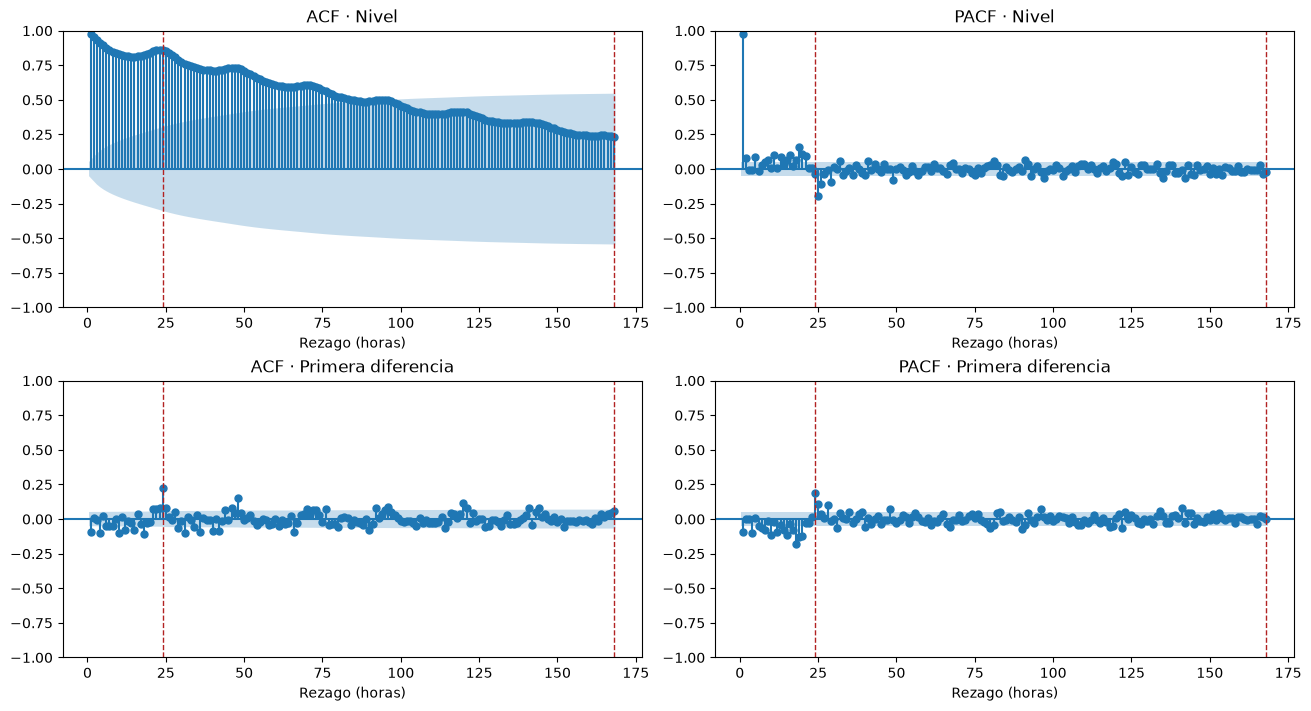

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
for (label, series), (ax_acf, ax_pacf) in zip(series_to_test.items(), axes, strict=True):
    lags = min(168, len(series) // 2 - 1)
    if lags < 1 or series.nunique() < 2:
        for ax in (ax_acf, ax_pacf):
            ax.set_title(f'{label}: serie insuficiente o constante')
        continue
    plot_acf(series, lags=lags, zero=False, fft=True, ax=ax_acf, title=f'ACF · {label}')
    plot_pacf(series, lags=lags, zero=False, method='ywm', ax=ax_pacf, title=f'PACF · {label}')
    for ax in (ax_acf, ax_pacf):
        for lag in (24, 168):
            if lag <= lags:
                ax.axvline(lag, color='firebrick', ls='--', lw=1)
        ax.set_xlabel('Rezago (horas)')
export(fig, '04_acf_pacf')

## 5. Descomposición estacional robusta (MSTL)

Descomposición aditiva con periodos de 24 y 168 horas. Cada periodo necesita más de dos ciclos completos en el tramo continuo. El ajuste robusto reduce la influencia de los picos al estimar tendencia y estacionalidad, sin borrarlos de la serie observada. Inspecciona los residuos y los efectos de borde; la descomposición usa información de ambos lados y no debe reutilizarse como característica causal.

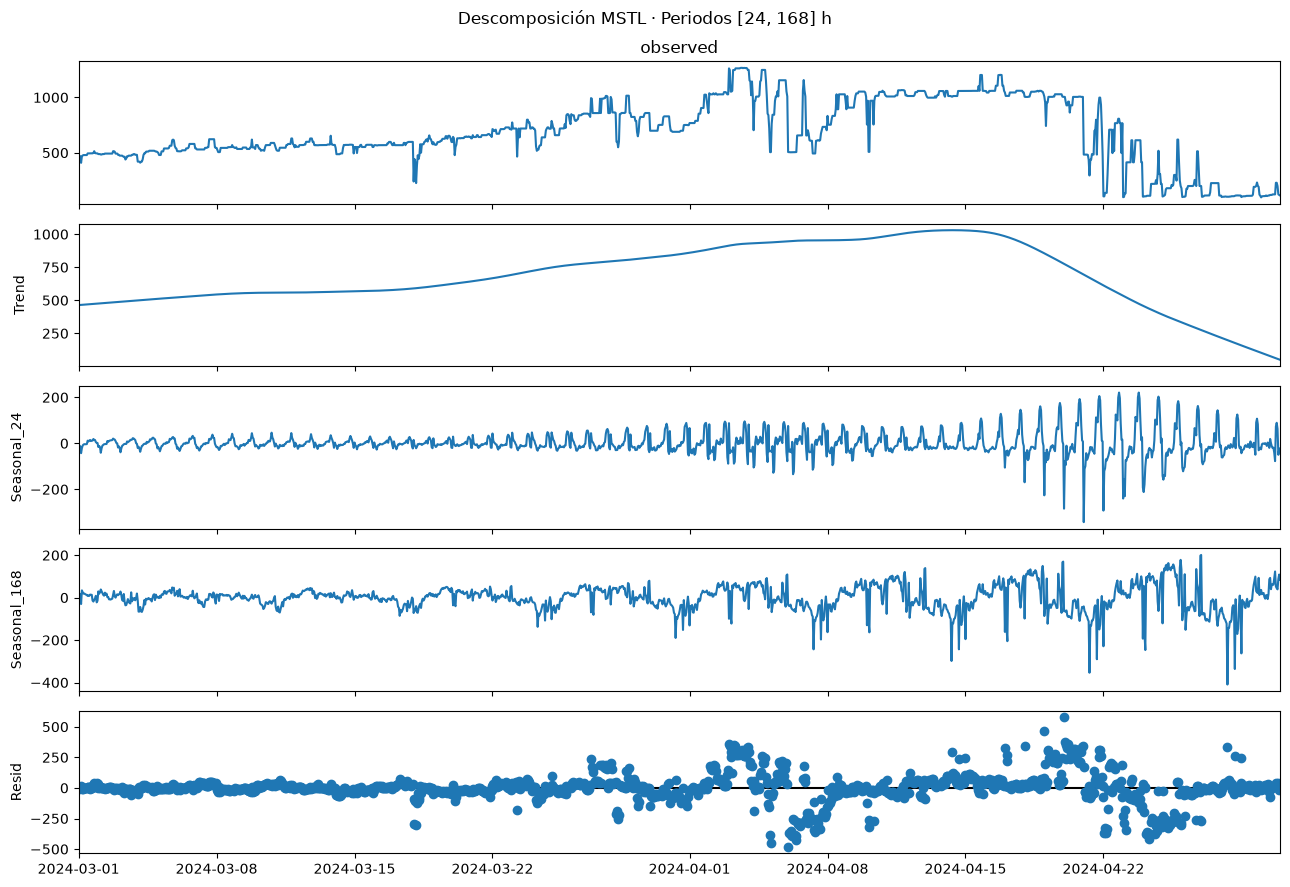

In [5]:
periods = [period for period in (24, 168) if len(block) > 2 * period]
if periods and block.nunique() >= 2:
    result = MSTL(block, periods=periods, stl_kwargs={'robust': True}).fit()
    fig = result.plot()
    fig.set_size_inches(13, 9)
    fig.suptitle(f'Descomposición MSTL · Periodos {periods} h')
    fig.tight_layout()
    export(fig, '05_descomposicion_mstl')
else:
    print('No hay más de dos ciclos diarios consecutivos no constantes; se omite MSTL.')

## 6. Contexto MEM y siguientes hipótesis

- Contrastar los días con picos con demanda nacional, generación hidráulica y térmica y aportes diarios por serie hidrológica. No extender observaciones diarias a horas como si cada hora fuese una medición independiente. La suma de demanda horaria para comparar días requiere revisar las 24 horas.
- Para separar estacionalidad de efectos de El Niño/La Niña, usar varios años y cruzar fases ENSO observadas de una fuente climática (p. ej., ONI de NOAA). El precio o la hidrología por sí solos no etiquetan la fase ENSO. Este notebook no descarga ni imputa etiquetas climáticas.
- Para modelado, registrar el momento de publicación de los datos y usar únicamente lo disponible en el instante del pronóstico. Las revisiones de liquidación y los valores operativos publicados después del cierre no son exógenas conocidas de antemano.

## 7. Precio nacional de XM (SINERGOX): auditoría y perfil de 2025

Bloque opcional, adaptado de `escenario_01.ipynb`. Activa `XM_ENABLED` para consultar `PrecBolsNaci` (`Sistema`) mediante `ReadDB` o indica una exportación XM en `XM_WIDE_CSV`. No se mezclan ventanas ni revisiones con el snapshot de SIMEM. Las estadísticas de Tukey (`1,5 × IQR` global) son un diagnóstico distinto del detector de picos por hora de la sección 2.

In [ ]:
from datetime import date

import numpy as np
from scipy.stats import gaussian_kde

from src.data.price_eda import audit_dataframe, compute_extended_statistics, melt_hourly_to_long, request_xm_price

XM_ENABLED = False
XM_WIDE_CSV = None  # Ruta absoluta o relativa a la raíz del repositorio.
xm_start, xm_end = date(2025, 1, 1), date(2025, 12, 31)

if XM_ENABLED:
    xm_raw = (pd.read_csv(root / XM_WIDE_CSV) if XM_WIDE_CSV is not None
              else request_xm_price(xm_start, xm_end))
    display(audit_dataframe(xm_raw, 'XM · formato ancho'))
    xm_long = melt_hourly_to_long(xm_raw, 'Precio')
    display(xm_raw[['Date', 'Values_Hour01', 'Values_Hour12', 'Values_Hour19', 'Values_Hour24']].head())
    xm_grid = pd.date_range(str(xm_start), pd.Timestamp(xm_end) + pd.DateOffset(days=1),
                            inclusive='left', freq='1h', tz='America/Bogota')
    xm_observed = xm_long.set_index('Timestamp')['Precio']
    if not xm_observed.index.isin(xm_grid).all():
        raise ValueError('XM devolvió fechas fuera de la ventana seleccionada.')
    xm_price = xm_observed.reindex(xm_grid)
    xm_absent = len(xm_grid) - len(xm_observed)
    xm_null = int(xm_observed.isna().sum())
    if not xm_price.notna().any():
        raise ValueError('No hay precios XM observados para analizar.')
    xm_stats = compute_extended_statistics(xm_price, 'Precio de bolsa XM (COP/kWh)')
    display(xm_stats.to_frame('Valor'))
else:
    print('Consulta XM desactivada. Activa XM_ENABLED para ejecutar esta sección.')

In [ ]:
if XM_ENABLED:
    fig, axes = plt.subplots(3, 1, figsize=(14, 12), layout='constrained')
    xm_price.plot(ax=axes[0], alpha=.35, label='Precio horario')
    xm_price.rolling(168, min_periods=24).mean().plot(ax=axes[0], color='firebrick', label='Media móvil 168 h')
    axes[0].set(title=f'Precio nacional XM · {xm_start} a {xm_end}', ylabel='COP/kWh', xlabel='Fecha local')
    axes[0].legend()

    clean_xm = xm_price.dropna()
    axes[1].hist(clean_xm, bins=60, density=True, color='seagreen', alpha=.45)
    if clean_xm.nunique() > 1:
        x_density = np.linspace(clean_xm.min(), clean_xm.max(), 512)
        axes[1].plot(x_density, gaussian_kde(clean_xm)(x_density), color='seagreen', label='KDE')
    for key, label, color in [('Media', 'Media', 'firebrick'), ('Mediana (50%)', 'Mediana', 'black'),
                              ('Umbral_Sup_IQR', 'Umbral Tukey superior', 'darkorange')]:
        axes[1].axvline(xm_stats[key], color=color, linestyle='--', label=f'{label}: {xm_stats[key]:.2f}')
    axes[1].set(title='Distribución y densidad del precio', xlabel='COP/kWh', ylabel='Densidad')
    axes[1].legend()

    xm_by_hour = xm_price.groupby(xm_price.index.hour + 1)
    xm_by_hour_values = dict(iter(xm_by_hour))
    axes[2].boxplot([xm_by_hour_values[h].dropna() if h in xm_by_hour_values else [] for h in range(1, 25)])
    axes[2].set(title='Perfil intradía XM', ylabel='COP/kWh', xlabel='Hora operativa (1 = 00:00; 24 = 23:00)')

    xm_figures = root / config['paths']['reports']['figures'] / 'xm'
    xm_figures.mkdir(parents=True, exist_ok=True)
    xm_figure = xm_figures / f'precio_bolsa_{xm_start}_{xm_end}.png'
    fig.savefig(xm_figure, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
    log_event(logging.INFO, 'figure_exported', source='XM', path=xm_figure)

### Conclusiones de la consulta XM

Resultados de `PrecBolsNaci` para el año calendario 2025, consultado el 18 de noviembre de 2026:

- **Cobertura completa:** las 8.760 horas esperadas están presentes, sin precios nulos ni marcas temporales duplicadas. No se imputaron datos.
- **Distribución asimétrica a la derecha:** la media (240,27 COP/kWh) supera a la mediana (163,93 COP/kWh) y la asimetría es 1,98. La mediana describe mejor el precio típico cuando los valores altos elevan el promedio.
- **Extremos relevantes:** Tukey marcó 826 horas (9,43 %). El máximo fue 2.224,01 COP/kWh el 14 de agosto a las 19:00. Estos valores se conservan; el criterio estadístico no demuestra que se haya activado el precio de escasez.
- **Perfil intradía:** la mayor mediana se observó a las 19:00 (403,27 COP/kWh) y la menor a las 02:00 (115,51 COP/kWh), en hora colombiana. Esto justifica evaluar el desempeño del pronóstico por hora, pero no identifica la causa de la diferencia. La media móvil de 168 horas resume el nivel semanal y puede ocultar episodios breves.

La siguiente celda recalcula estas métricas para la ventana ejecutada. Los valores publicados pueden cambiar con revisiones posteriores.

In [ ]:
if XM_ENABLED:
    hour_medians = xm_by_hour.median().dropna()
    print(f'Cobertura: {clean_xm.size:,} de {len(xm_grid):,} horas ({clean_xm.size / len(xm_grid):.2%}); '
          f'{xm_absent:,} sin registro y {xm_null:,} con precio nulo. Sin marcas temporales duplicadas.')
    print(f'Media: {xm_stats["Media"]:.2f}; mediana: {xm_stats["Mediana (50%)"]:.2f}; '
          f'asimetría: {xm_stats["Asimetria"]:.2f}.')
    print(f'Tukey: {xm_stats["Outliers_IQR_Count"]:,} atípicos ({xm_stats["Outliers_IQR_%"]:.2f} %). '
          f'Pico observado: {clean_xm.max():.2f} COP/kWh el {clean_xm.idxmax():%Y-%m-%d %H:%M %Z}.')
    print(f'La mediana intradía más alta es {hour_medians.max():.2f} COP/kWh a las '
          f'{hour_medians.idxmax() - 1:02d}:00; la más baja es {hour_medians.min():.2f} COP/kWh a las '
          f'{hour_medians.idxmin() - 1:02d}:00 (hora colombiana).')